# Titanic Survival Prediction

**Project goal:** Predict whether a passenger survived the Titanic disaster using passenger information. This notebook explores the data, prepares features, compares classification models, evaluates performance, and creates a Kaggle submission.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Import Libraries and Load Data

Import the analysis libraries and read the labeled training dataset.


In [3]:
df = pd.read_csv('/kaggle/input/competitions/titanic/train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Exploratory Data Analysis (EDA)

Inspect descriptive statistics, numerical relationships, missing values, and the age distribution.


In [4]:
df.describe()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
df.corr(numeric_only=True)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658
Survived,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
Pclass,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
Age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
Parch,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
Fare,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


### 2.1 Missing Values

Identify columns with missing observations before preprocessing.


In [6]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
df['Age'].value_counts()

Age
24.00    30
22.00    27
18.00    26
28.00    25
30.00    25
         ..
24.50     1
0.67      1
0.42      1
34.50     1
74.00     1
Name: count, Length: 88, dtype: int64

In [8]:
df['Age'].mean()

np.float64(29.69911764705882)

In [9]:
df['Age'].max()

80.0

In [10]:
df['Age'].median()

28.0

In [11]:
df['Age'] = df['Age'].sort_values(ascending=True)

In [12]:
df['Age']

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888     NaN
889    26.0
890    32.0
Name: Age, Length: 891, dtype: float64

### 2.2 Age Distribution

Visualize passenger ages.


<Axes: ylabel='Frequency'>

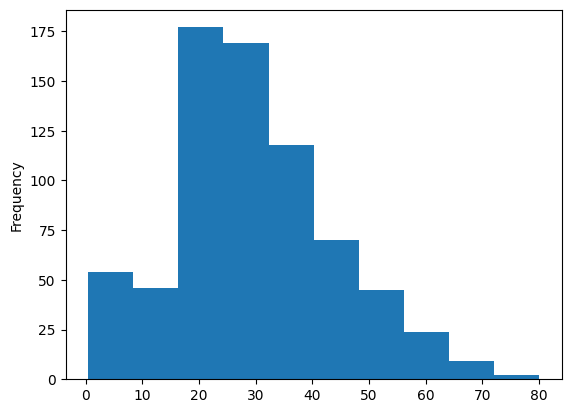

In [13]:
df['Age'].plot.hist()

## 3. Data Cleaning and Preprocessing

Handle missing ages and embarkation values. Create an indicator for cabin information.


In [14]:
df['Age'] = df['Age'].fillna(df['Age'].median())

In [15]:
df['Cabin']

0       NaN
1       C85
2       NaN
3      C123
4       NaN
       ... 
886     NaN
887     B42
888     NaN
889    C148
890     NaN
Name: Cabin, Length: 891, dtype: object

In [16]:
df['Has_Cabin'] = df['Cabin'].notna().astype(int)
df = df.drop('Cabin' ,axis = 1)

In [17]:
df['Has_Cabin'].value_counts()

Has_Cabin
0    687
1    204
Name: count, dtype: int64

In [18]:
df  = df.dropna(subset=['Embarked'])
df.isna().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
Has_Cabin      0
dtype: int64

## 4. Survival Patterns

Compare survival rates by sex and inspect the class distribution.


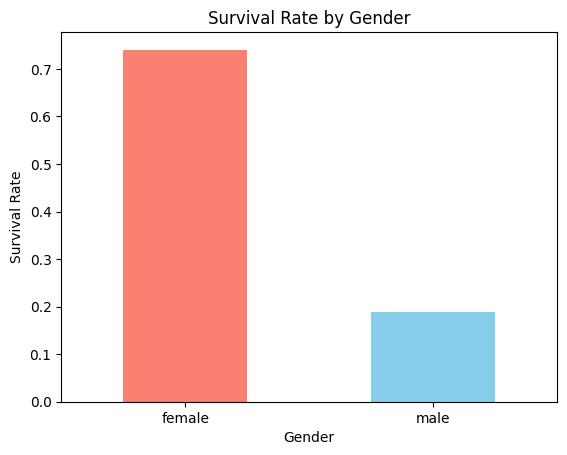

In [19]:
df.groupby('Sex')['Survived'].mean().plot(kind ='bar' , color = ['salmon' , 'skyblue'])
plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate')
plt.xticks(rotation=0)
plt.show()

<Axes: xlabel='Sex', ylabel='count'>

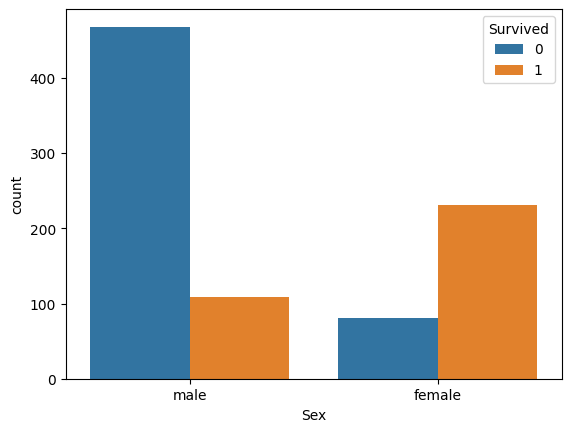

In [20]:
sns.countplot(data=df , x = 'Sex' , hue = 'Survived')

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  889 non-null    int64  
 1   Survived     889 non-null    int64  
 2   Pclass       889 non-null    int64  
 3   Name         889 non-null    object 
 4   Sex          889 non-null    object 
 5   Age          889 non-null    float64
 6   SibSp        889 non-null    int64  
 7   Parch        889 non-null    int64  
 8   Ticket       889 non-null    object 
 9   Fare         889 non-null    float64
 10  Embarked     889 non-null    object 
 11  Has_Cabin    889 non-null    int64  
dtypes: float64(2), int64(6), object(4)
memory usage: 90.3+ KB


## 5. Feature Selection and Encoding

Select predictors and convert categorical values into numerical model inputs.


In [22]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Has_Cabin']
X = df[features].copy()
y = df['Survived']

# Apply get_dummies and convert to integers
X = pd.get_dummies(X, columns=['Sex', 'Embarked'], drop_first=True)
X = X.astype(int)

## 6. Model Training: Logistic Regression

Split data into training and validation sets, standardize features, and train a baseline classifier.


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = LogisticRegression()
model.fit(X_train , y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test , y_pred)
print(f'Accuracy: {accuracy}')
print(classification_report(y_test , y_pred))

Accuracy: 0.7921348314606742
              precision    recall  f1-score   support

           0       0.85      0.80      0.82       109
           1       0.71      0.78      0.74        69

    accuracy                           0.79       178
   macro avg       0.78      0.79      0.78       178
weighted avg       0.80      0.79      0.79       178



## 7. Model Training: Random Forest

Train a tree-based ensemble and inspect classification metrics.


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
np.random.seed(42)
clf = RandomForestClassifier(n_estimators = 100)
clf.fit(X_train , y_train)
clf_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test , clf_pred)
print(f'Accuracy: {accuracy}')
print(classification_report(y_test , clf_pred))

Accuracy: 0.7752808988764045
              precision    recall  f1-score   support

           0       0.83      0.79      0.81       109
           1       0.69      0.75      0.72        69

    accuracy                           0.78       178
   macro avg       0.76      0.77      0.77       178
weighted avg       0.78      0.78      0.78       178



## 8. Model Training: XGBoost

Train a gradient-boosted tree classifier for comparison.


In [25]:
from xgboost import XGBClassifier
np.random.seed(42)
xgb = XGBClassifier()
xgb.fit(X_train , y_train)
xgb_pred = xgb.predict(X_test)
accuracy = accuracy_score(y_test , xgb_pred)
print(f'Accuracy: {accuracy}')
print(classification_report(y_test , xgb_pred))

Accuracy: 0.8089887640449438
              precision    recall  f1-score   support

           0       0.84      0.84      0.84       109
           1       0.75      0.75      0.75        69

    accuracy                           0.81       178
   macro avg       0.80      0.80      0.80       178
weighted avg       0.81      0.81      0.81       178



## 9. Cross-Validation

Estimate Random Forest accuracy across five folds.


In [26]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(clf, X, y, cv=5, scoring='accuracy')
print("Scores for each fold:", cv_scores)
cv_scores.mean()

Scores for each fold: [0.78089888 0.78651685 0.83146067 0.78651685 0.85875706]


np.float64(0.8088300641147719)

## 10. Hyperparameter Tuning with GridSearchCV

Search a reduced Random Forest parameter grid and evaluate the selected model.


In [27]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [None, 5, 10, 20],
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
grid_search.fit(X_train , y_train)
best_params = grid_search.best_params_
best_score = grid_search.best_score_
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
accuracy = accuracy_score(y_test , y_pred)
print(f'Accuracy: {accuracy}')
print(classification_report(y_test , y_pred))

Accuracy: 0.7921348314606742
              precision    recall  f1-score   support

           0       0.83      0.83      0.83       109
           1       0.73      0.74      0.73        69

    accuracy                           0.79       178
   macro avg       0.78      0.78      0.78       178
weighted avg       0.79      0.79      0.79       178



## 11. Prepare the Kaggle Test Dataset

Load the unlabeled test data and apply feature preparation.


In [28]:
test_df = pd.read_csv('/kaggle/input/competitions/titanic/test.csv')

In [29]:
passenger_ids = test_df['PassengerId']

In [30]:
test_df['Age'] = test_df['Age'].fillna(df['Age'].median())

In [31]:
test_df['Fare'] = test_df['Fare'].fillna(df['Fare'].median())

In [32]:
test_df['Has_Cabin'] = test_df['Cabin'].notna().astype(int)

In [33]:
test_features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Has_Cabin']
X_test_final = test_df[test_features].copy()

# Encode categorical variables using get_dummies (matching your training columns)
X_test_final = pd.get_dummies(X_test_final, columns=['Sex', 'Embarked'], drop_first=True)
X_test_final = X_test_final.astype(int)

In [34]:
X_test_final = X_test_final.reindex(columns=X.columns, fill_value=0)

## 12. Generate Final Predictions

Predict survival for the Kaggle test passengers.


In [35]:
final_predictions = best_model.predict(X_test_final)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


## 13. Create the Submission File

Write passenger IDs and predicted labels into a CSV file.


In [36]:
submission = pd.DataFrame({
    'PassengerId': passenger_ids,
    'Survived': final_predictions
})

In [37]:
submission.to_csv('titanic_submission.csv', index=False)

In [38]:
print("Submission file successfully created and saved as 'titanic_submission.csv'!")
print(submission.head())

Submission file successfully created and saved as 'titanic_submission.csv'!
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         0


## 14. Conclusion and Next Steps

This notebook explores the Titanic data and compares Logistic Regression, Random Forest, and XGBoost, with cross-validation and Random Forest tuning. Review the printed scores to identify the strongest model. Before using the final Kaggle predictions, ensure test features receive the same preprocessing as the training features.
